# 02. Latih Ulang Model Huruf BISINDO

Notebook kedua. Data diambil dari NPZ hasil **01_preprocessing_dataset_foto.ipynb**, lalu dipakai untuk melatih model `ml/models/svm_rbf_bisindo.joblib`, yaitu model yang dipakai server (`POST /api/predict`) untuk menjawab aplikasi HP.

1. Muat NPZ dan bagi data **per kelompok foto**, supaya data uji benar-benar belum pernah dilihat model.
2. Lihat kenapa bentuk frame kamera HP (potret 9:16) penting.
3. (Opsional) cari pengaturan `C` dan `gamma`.
4. Latih model dan nilai pada foto uji.
5. Hitung metrik lengkap: accuracy, precision, recall, F1-score (weighted dan macro), dan laporan per huruf.
6. Lihat huruf mana yang masih sering tertukar.
7. (Opsional) simpan model untuk dipakai server.

Secara bawaan notebook ini **tidak menimpa model server**. Ubah `SIMPAN_MODEL = True` bila ingin menyimpannya.

In [1]:
import json
import sys
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    f1_score, precision_score, recall_score,
)
from sklearn.model_selection import StratifiedGroupKFold

warnings.filterwarnings("ignore")

# Notebook ada di ml/notebooks, sedangkan modul ada di ml/src.
ML_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd() / "ml"
SRC_DIR = ML_DIR / "src"
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

from dataset.augment_landmarks import augment_dataset, stretch_aspect
from dataset.data_loader import FEATURE_COUNT
from training.retrain_from_photos import (
    PHONE_ASPECT, aspect_scores, pick_best, search, server_predict,
)
from training.train_svm import LABEL_MAP_FILENAME, MODEL_FILENAME, build_model

# ---------------- Pengaturan: ubah di sini untuk mencoba sendiri ----------------
NPZ_PATH = ML_DIR / "data" / "processed" / "dataset_bisindo_landmarks_foto.npz"  # hasil notebook 01
MODELS_DIR = ML_DIR / "models"

C = 30.0                 # makin besar makin "hafal" data latih
GAMMA = 0.004            # makin besar batas antar huruf makin berliku
SALINAN_AUGMENTASI = 3  # berapa salinan acak dibuat dari tiap baris latih
GOYANGAN = (0.015, 0.035, 0.06)  # goyangan titik per salinan; besar = meniru tangan jauh
SEED = 42

JALANKAN_PENCARIAN = False  # True = cari C dan gamma lagi (beberapa menit)
SIMPAN_MODEL = False        # True = timpa ml/models/svm_rbf_bisindo.joblib

# Augmentasi meniru frame kamera HP: potret 9:16, jadi tangan tampak 16/9 kali lebih lebar.
AUGMENTASI = dict(aspects=(PHONE_ASPECT,), aspect_jitter=0.12, include_original=False, point_noise=GOYANGAN)
print("NPZ:", NPZ_PATH, "| ada" if NPZ_PATH.exists() else "| TIDAK ADA, jalankan notebook 01 dulu")

NPZ: C:\POLINEMA\SEMESTER 5\bisindo\ml\data\processed\dataset_bisindo_landmarks_foto.npz | ada


## 1. Muat NPZ dan bagi data per kelompok foto
20% kelompok foto disisihkan sebagai data uji. Karena satu kelompok selalu utuh di satu sisi, foto yang nyaris kembar tidak bisa "bocor" dari data latih ke data uji.

In [2]:
data = np.load(NPZ_PATH, allow_pickle=True)
features = data["X"].astype(np.float32)
labels = data["labels"].astype(str)
groups = data["groups"]
class_names = sorted(set(labels))
target = np.array([class_names.index(h) for h in labels])
is_flip = np.zeros(len(features), dtype=bool)  # data tanpa versi cermin

train_index, test_index = next(
    StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED).split(features, target, groups)
)
x_train, y_train, g_train = features[train_index], target[train_index], groups[train_index]
x_test, y_test = features[test_index], target[test_index]

print(f"Data          : {features.shape[0]} foto x {features.shape[1]} fitur, {len(class_names)} huruf")
print(f"Kelompok foto : {len(np.unique(groups))}")
print(f"Data latih    : {len(x_train)} foto")
print(f"Data uji      : {len(x_test)} foto")

Data          : 5789 foto x 127 fitur, 26 huruf
Kelompok foto : 2826
Data latih    : 4410 foto
Data uji      : 1379 foto


## 2. Kenapa bentuk frame kamera penting
MediaPipe memberi koordinat x dan y dalam rentang 0 sampai 1 terhadap lebar dan tinggi gambar. Foto dataset berbentuk persegi, sedangkan frame kamera HP berbentuk potret 9:16. Aplikasi mengirim koordinat itu apa adanya, sehingga di HP tangan yang sama tampak sekitar 1,78 kali lebih lebar.

Gambar di bawah menunjukkan satu sampel yang sama pada dua bentuk frame. Model yang hanya pernah melihat bentuk kiri akan kesulitan mengenali bentuk kanan.

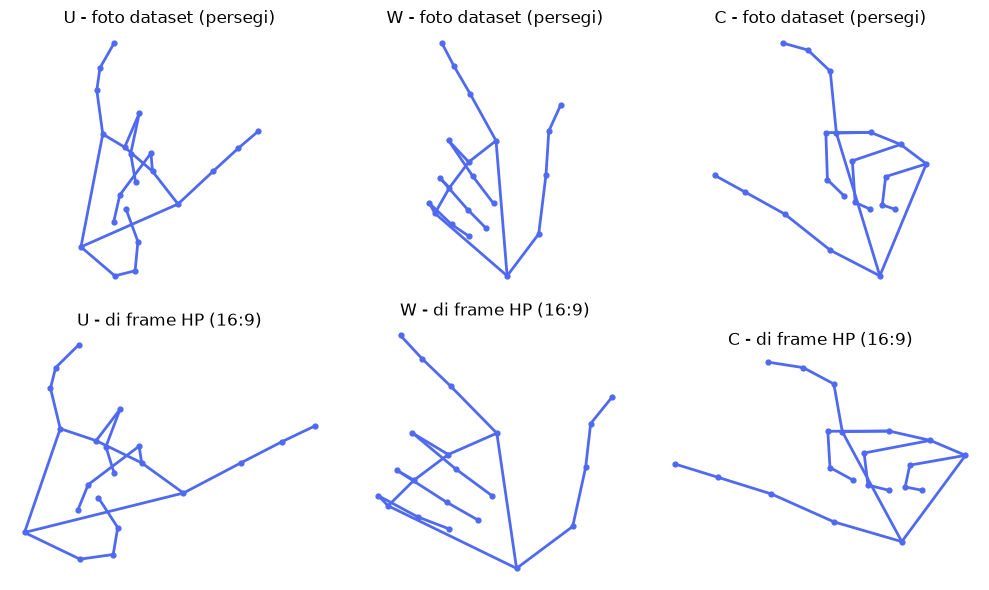

In [3]:
RANGKA = [(0,1),(1,2),(2,3),(3,4),(0,5),(5,6),(6,7),(7,8),(5,9),(9,10),(10,11),(11,12),
          (9,13),(13,14),(14,15),(15,16),(13,17),(17,18),(18,19),(19,20),(0,17)]

def gambar_tangan(ax, baris, judul):
    titik = baris[:126].reshape(42, 3)
    for awal, warna in ((0, "#4F6AF0"), (21, "#F5A524")):
        tangan = titik[awal:awal + 21]
        if not np.any(tangan):
            continue
        for a, b in RANGKA:
            ax.plot(tangan[[a, b], 0], tangan[[a, b], 1], color=warna, lw=2)
        ax.scatter(tangan[:, 0], tangan[:, 1], color=warna, s=12)
    ax.invert_yaxis(); ax.set_aspect("equal"); ax.set_title(judul); ax.axis("off")

contoh = x_test[[np.flatnonzero(y_test == class_names.index(h))[0] for h in ("U", "W", "C")]]
fig, axes = plt.subplots(2, 3, figsize=(10, 6))
for kolom, huruf in enumerate(("U", "W", "C")):
    gambar_tangan(axes[0, kolom], contoh[kolom], f"{huruf} - foto dataset (persegi)")
    gambar_tangan(axes[1, kolom], stretch_aspect(contoh[kolom:kolom + 1], PHONE_ASPECT)[0], f"{huruf} - di frame HP (16:9)")
plt.tight_layout(); plt.show()

## 3. (Opsional) Cari pengaturan C dan gamma
Tiap kombinasi dilatih dan dinilai dengan validasi silang berkelompok di data latih saja; data uji tidak disentuh. Bila beberapa kombinasi hasilnya setara, dipilih `C` terkecil karena modelnya lebih sederhana dan lebih kecil risikonya menghafal data.

In [4]:
if JALANKAN_PENCARIAN:
    tabel = search(
        x_train, y_train, g_train,
        c_grid=(1.0, 3.0, 10.0, 30.0), gamma_grid=(0.004, 0.008, 0.016),
        copies_grid=(SALINAN_AUGMENTASI,), folds=3, seed=SEED, jobs=-1,
        aug=AUGMENTASI, score_aspects=(1.6, PHONE_ASPECT, 2.0),
    )
    display(pd.DataFrame(tabel))
    terpilih = pick_best(tabel)
    C, GAMMA = terpilih["C"], terpilih["gamma"]
print(f"Dipakai: C={C}, gamma={GAMMA}, salinan augmentasi={SALINAN_AUGMENTASI}")

Dipakai: C=30.0, gamma=0.004, salinan augmentasi=3


## 4. Latih model dan nilai pada foto uji
Data latih diperbanyak dengan salinan acak (rotasi kecil, rasio frame HP, dan goyangan titik). Goyangan dibuat bertingkat: salinan dengan goyangan besar meniru tangan yang **jauh dari kamera**, karena titik MediaPipe kurang presisi saat tangan tampak kecil. Tanpa ini, D dari jauh hanya terbaca 40-60%. Penilaian meniru server: tiap sampel dicoba dalam bentuk asli, dicerminkan, dan dengan urutan tangan ditukar, lalu dipakai jawaban yang paling yakin.

Selisih besar antara akurasi **latih** dan **uji** adalah tanda overfitting.

In [5]:
x_aug, y_aug = augment_dataset(x_train, y_train, SALINAN_AUGMENTASI, seed=SEED, **AUGMENTASI)
model = build_model(c_value=C, gamma=GAMMA, random_state=SEED)
model.fit(x_aug, y_aug)

prediksi = lambda matriks: server_predict(model, matriks)
skor_latih = aspect_scores(prediksi, x_train[~is_flip[train_index]], y_train[~is_flip[train_index]])
skor_uji = aspect_scores(prediksi, x_test, y_test)

hasil = pd.DataFrame({"Latih": skor_latih, "Uji": skor_uji})
hasil["Selisih"] = hasil["Latih"] - hasil["Uji"]
hasil.index.name = "Rasio frame"
display(hasil.style.format("{:.2%}"))
print(f"Akurasi pada rasio frame HP (16:9): {skor_uji['16:9']:.2%} dari {len(x_test)} foto uji")

,Latih,Uji,Selisih
Rasio frame,,,
persegi,92.86%,75.42%,17.44%
4:3,97.26%,84.19%,13.06%
1.60,98.41%,87.24%,11.18%
16:9,98.37%,87.24%,11.13%
2.00,98.23%,87.09%,11.14%


Akurasi pada rasio frame HP (16:9): 87.24% dari 1379 foto uji


## 5. Metrik lengkap: accuracy, precision, recall, F1-score
Dihitung pada **foto uji** (yang tidak ikut latihan) dengan bentuk frame kamera HP (16:9), dan cara menebak sama seperti server.

- **Accuracy**: persentase foto yang hurufnya ditebak benar.
- **Precision**: dari semua tebakan huruf X, berapa yang memang X.
- **Recall**: dari semua foto huruf X, berapa yang berhasil ditebak X.
- **F1-score**: gabungan precision dan recall (rata-rata harmonis).
- **Weighted** menimbang tiap huruf sesuai jumlah fotonya; **macro** menganggap semua huruf sama penting, jadi huruf yang fotonya sedikit (misalnya Y) lebih terasa pengaruhnya.

Baris **Latih** dihitung pada data latih. Selisih besar antara latih dan uji adalah tanda overfitting.

In [6]:
def hitung_metrik(y_benar, y_tebak):
    return {
        "Accuracy": accuracy_score(y_benar, y_tebak),
        "Precision (weighted)": precision_score(y_benar, y_tebak, average="weighted", zero_division=0),
        "Recall (weighted)": recall_score(y_benar, y_tebak, average="weighted", zero_division=0),
        "F1-score (weighted)": f1_score(y_benar, y_tebak, average="weighted", zero_division=0),
        "Precision (macro)": precision_score(y_benar, y_tebak, average="macro", zero_division=0),
        "Recall (macro)": recall_score(y_benar, y_tebak, average="macro", zero_division=0),
        "F1-score (macro)": f1_score(y_benar, y_tebak, average="macro", zero_division=0),
    }


pred_uji = prediksi(stretch_aspect(x_test, PHONE_ASPECT))
pred_latih = prediksi(stretch_aspect(x_train, PHONE_ASPECT))

ringkasan_metrik = pd.DataFrame({
    "Latih": hitung_metrik(y_train, pred_latih),
    "Uji": hitung_metrik(y_test, pred_uji),
})
ringkasan_metrik["Selisih (latih - uji)"] = ringkasan_metrik["Latih"] - ringkasan_metrik["Uji"]
display(ringkasan_metrik.style.format("{:.4f}").set_caption("Metrik pada frame kamera HP (16:9)"))

benar = int((pred_uji == y_test).sum())
print(f"Foto uji: {len(y_test)} | benar {benar} | salah {len(y_test) - benar}")

,Latih,Uji,Selisih (latih - uji)
Accuracy,0.9837,0.8724,0.1113
Precision (weighted),0.9842,0.9363,0.0479
Recall (weighted),0.9837,0.8724,0.1113
F1-score (weighted),0.9837,0.8817,0.1020
Precision (macro),0.9851,0.8851,0.1000
Recall (macro),0.9842,0.8935,0.0908
F1-score (macro),0.9844,0.8622,0.1222


Foto uji: 1379 | benar 1203 | salah 176


### Laporan per huruf
`support` adalah jumlah foto uji untuk huruf tersebut. Huruf dengan F1 di bawah 0,90 ditandai merah.

In [7]:
laporan_huruf = pd.DataFrame(
    classification_report(y_test, pred_uji, target_names=class_names, output_dict=True, zero_division=0)
).T
laporan_huruf["support"] = laporan_huruf["support"].astype(int)
per_huruf = laporan_huruf.loc[class_names]


def tandai(nilai):
    return "color: #E5484D; font-weight: bold" if nilai < 0.90 else ""


display(per_huruf.style.format({"precision": "{:.3f}", "recall": "{:.3f}", "f1-score": "{:.3f}"})
        .map(tandai, subset=["f1-score"])
        .set_caption("Precision, recall, dan F1 per huruf (foto uji, frame HP)"))
display(laporan_huruf.loc[["macro avg", "weighted avg"]].style.format("{:.4f}"))

lemah = per_huruf.sort_values("f1-score").head(5)
print("Lima huruf terlemah:", ", ".join(f"{h} ({v:.2f})" for h, v in lemah["f1-score"].items()))

,precision,recall,f1-score,support
A,0.973,0.923,0.947,39
B,1.000,1.000,1.000,19
C,0.953,0.685,0.797,89
D,0.938,0.833,0.882,18
E,0.967,0.983,0.975,59
F,0.985,0.957,0.971,69
G,1.000,1.000,1.000,41
H,1.000,0.852,0.920,27
I,0.987,1.000,0.994,77
J,1.000,1.000,1.000,55


,precision,recall,f1-score,support
macro avg,0.8851,0.8935,0.8622,1379.0000
weighted avg,0.9363,0.8724,0.8817,1379.0000


Lima huruf terlemah: N (0.30), M (0.40), L (0.47), U (0.53), W (0.77)


## 6. Huruf mana yang masih sering tertukar
Dihitung pada foto uji dengan rasio frame HP (16:9).

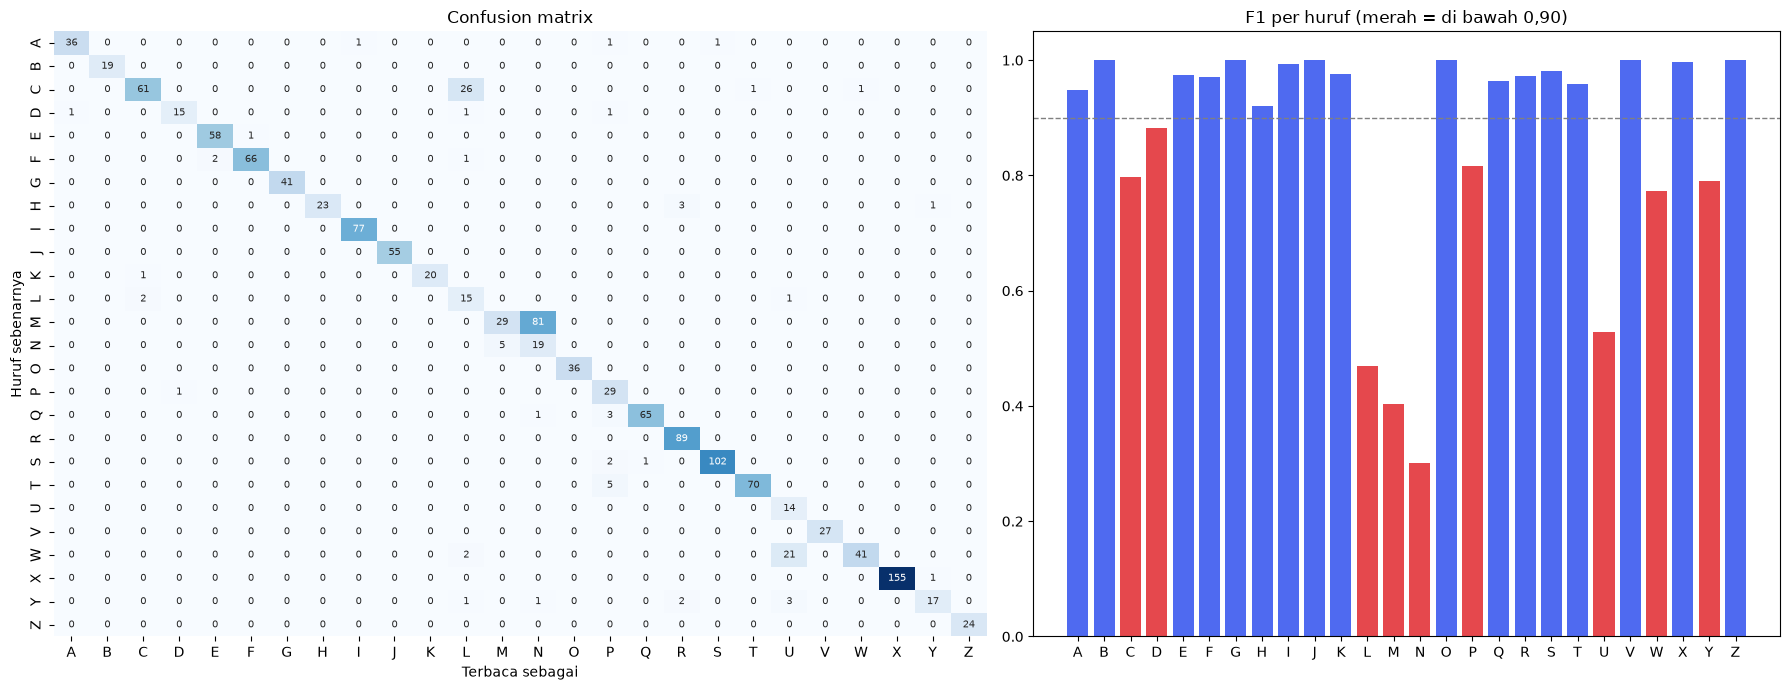

,Huruf sebenarnya,Terbaca sebagai,Jumlah
0,M,N,81
1,C,L,26
2,W,U,21
3,N,M,5
4,T,P,5
5,H,R,3
6,Q,P,3
7,Y,U,3
8,F,E,2
9,L,C,2


In [8]:
pred_hp = pred_uji  # sama dengan bagian 5
laporan = classification_report(y_test, pred_hp, target_names=class_names, output_dict=True, zero_division=0)
matriks = confusion_matrix(y_test, pred_hp)

fig, axes = plt.subplots(1, 2, figsize=(18, 7), gridspec_kw={"width_ratios": [1.25, 1]})
sns.heatmap(matriks, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[0],
            xticklabels=class_names, yticklabels=class_names, annot_kws={"size": 7})
axes[0].set_xlabel("Terbaca sebagai"); axes[0].set_ylabel("Huruf sebenarnya"); axes[0].set_title("Confusion matrix")

f1 = pd.Series({h: laporan[h]["f1-score"] for h in class_names})
axes[1].bar(f1.index, f1.values, color=["#E5484D" if v < 0.9 else "#4F6AF0" for v in f1.values])
axes[1].axhline(0.9, color="gray", ls="--", lw=1); axes[1].set_ylim(0, 1.05); axes[1].set_title("F1 per huruf (merah = di bawah 0,90)")
plt.tight_layout(); plt.show()

tertukar = [(class_names[a], class_names[b], int(matriks[a, b]))
            for a in range(len(class_names)) for b in range(len(class_names)) if a != b and matriks[a, b] > 0]
display(pd.DataFrame(sorted(tertukar, key=lambda t: -t[2])[:10], columns=["Huruf sebenarnya", "Terbaca sebagai", "Jumlah"]))

## 7. (Opsional) Simpan model untuk server
Model yang disimpan dilatih ulang pada **seluruh** data dengan pengaturan yang sama, supaya tidak ada foto yang terbuang. Angka akurasi yang sah tetap angka di bagian 4.

Setelah disimpan, jalankan server lokal (`python web/run.py`) lalu uji lewat aplikasi di HP. Untuk hasil lengkap beserta `metrics.json`, pakai skrip:

```bash
python ml/src/training/retrain_from_photos.py --csv ml/data/processed/landmarks_train_tanpa_cermin.csv --group-threshold 0.01 --no-original --C 30 --gamma 0.004 --copies 3 --drop-single-hand B P --point-noise 0.015 0.035 0.06
```

In [9]:
if SIMPAN_MODEL:
    x_semua, y_semua = augment_dataset(features, target, SALINAN_AUGMENTASI, seed=SEED, **AUGMENTASI)
    model_akhir = build_model(c_value=C, gamma=GAMMA, random_state=SEED)
    model_akhir.fit(x_semua, y_semua)
    joblib.dump(model_akhir, MODELS_DIR / MODEL_FILENAME, compress=3)
    (MODELS_DIR / LABEL_MAP_FILENAME).write_text(
        json.dumps({"classes": class_names, "feature_count": FEATURE_COUNT}, indent=2), encoding="utf-8")
    print("Model disimpan ke", MODELS_DIR / MODEL_FILENAME)
else:
    print("SIMPAN_MODEL = False, model di ml/models tidak diubah.")

SIMPAN_MODEL = False, model di ml/models tidak diubah.
